In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Markdown, Image, display
P = ROOT / "data" / "processed"
F = ROOT / "docs" / "figures"
pd.options.display.float_format = "{:,.4f}".format
def table(name): return pd.read_csv(P / name)
def summary(name): return json.loads((P / name).read_text())
def fig(name): display(Image(filename=str(F / name)))
print("Simulated data. Every number below is read from executed pipeline outputs.")


Simulated data. Every number below is read from executed pipeline outputs.


# M6. Renewal model and customer lifetime value (Simulated data)

Renewal is modelled with a binomial GLM and a GBM. CLV for a new policy is

$$\text{CLV} = -a + \sum_{t=1}^{H} d^{\,t-1}\, S_t\,(P_t - c_t), \qquad S_1 = 1,\; S_t = \prod_{k=1}^{t-1} \rho_k$$

with acquisition cost $a$, discount factor $d$, horizon $H$, survival $S_t$, renewal probabilities $\rho_k$, premium $P_t$ and cost $c_t$. Year 1 is not discounted. Premium growth, market growth and cost growth are configuration inputs.

In [2]:
table("m6_renewal_metrics__simulated_data.csv")

,split,model,roc_auc,log_loss,brier,mean_prediction,observed_rate
0,validation,naive,0.6014,0.5154,0.1675,0.7836,0.7805
1,validation,glm,0.6508,0.5009,0.1623,0.7836,0.7805
2,validation,gbm,0.6499,0.5013,0.1624,0.7833,0.7805
3,test,naive,0.6016,0.5133,0.1666,0.7846,0.7821
4,test,glm,0.6534,0.4987,0.1616,0.7841,0.7821
5,test,gbm,0.6519,0.4991,0.1617,0.7836,0.7821


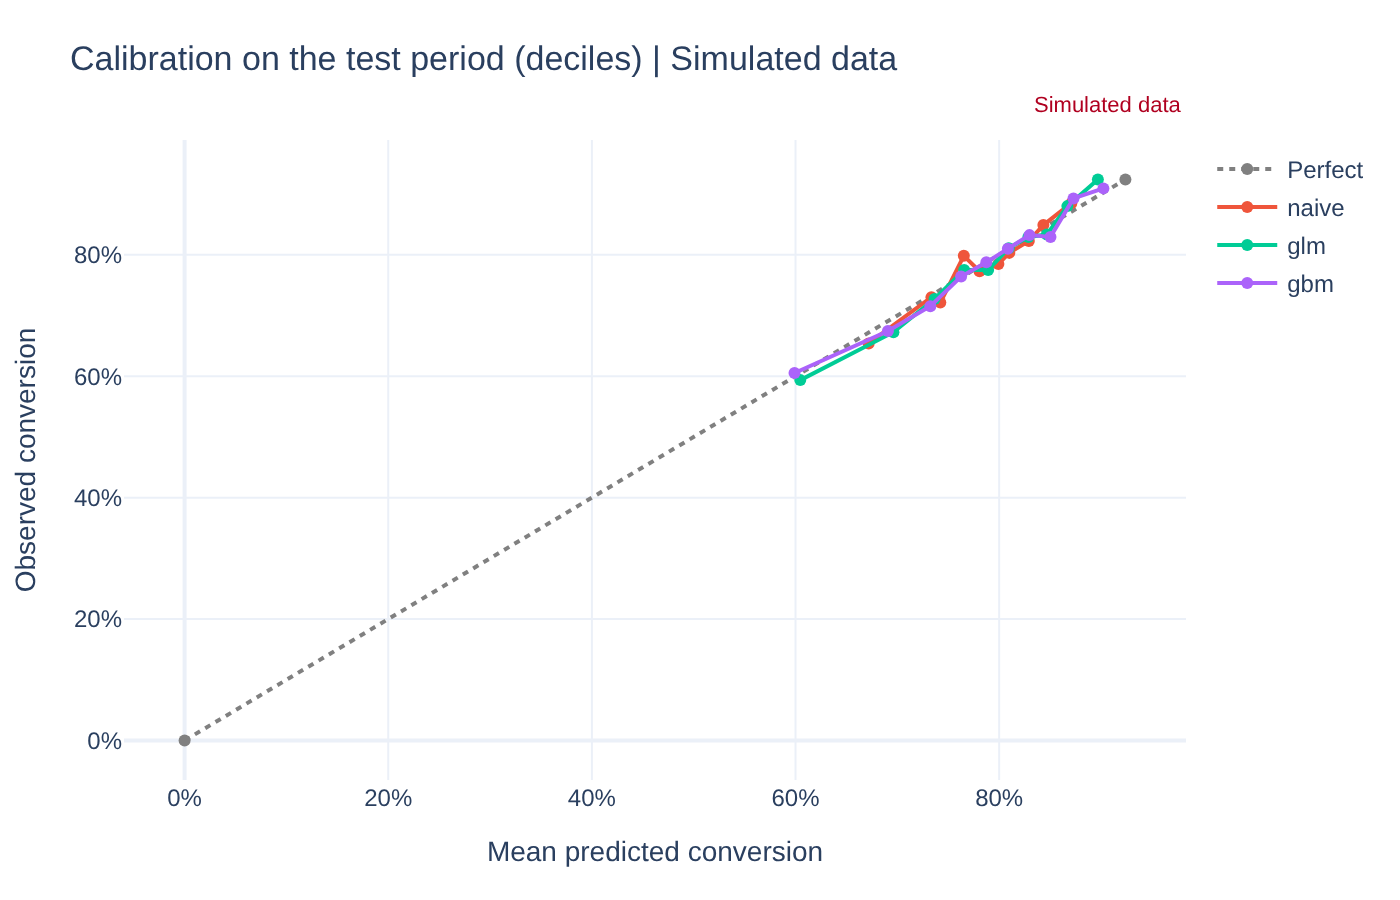

In [3]:
fig("m6_renewal_calibration__simulated_data.png")

In [4]:
table("m6_clv_by_segment__simulated_data.csv")

,segment,first_year_contribution_per_policy,clv_per_policy,retention_year1_renewal,expected_policy_years,clv_to_first_year_multiple
0,17-24|London_SE,562.1697,"1,582.0804",0.6054,2.4607,2.8142
1,17-24|Midlands_East,325.6126,"1,041.8393",0.6343,2.5917,3.1996
2,17-24|North_West_Rest,294.2357,970.7433,0.6431,2.6331,3.2992
3,25-34|London_SE,199.5333,799.3190,0.6986,2.9095,4.0059
4,25-34|Midlands_East,83.7316,470.5451,0.7234,3.0443,5.6197
5,25-34|North_West_Rest,68.4105,429.2826,0.7293,3.0770,6.2751
6,35-49|London_SE,151.5562,680.3124,0.7221,3.0387,4.4888
7,35-49|Midlands_East,54.0131,385.3419,0.7373,3.1204,7.1342
8,35-49|North_West_Rest,38.1128,345.2426,0.7525,3.2086,9.0584
9,50-64|London_SE,79.7683,500.5002,0.7604,3.2543,6.2744


Mean CLV per policy **521.3** versus mean first-year contribution **100.5**. 10 of 15 segments take a different new business action under CLV than under the first-year objective.

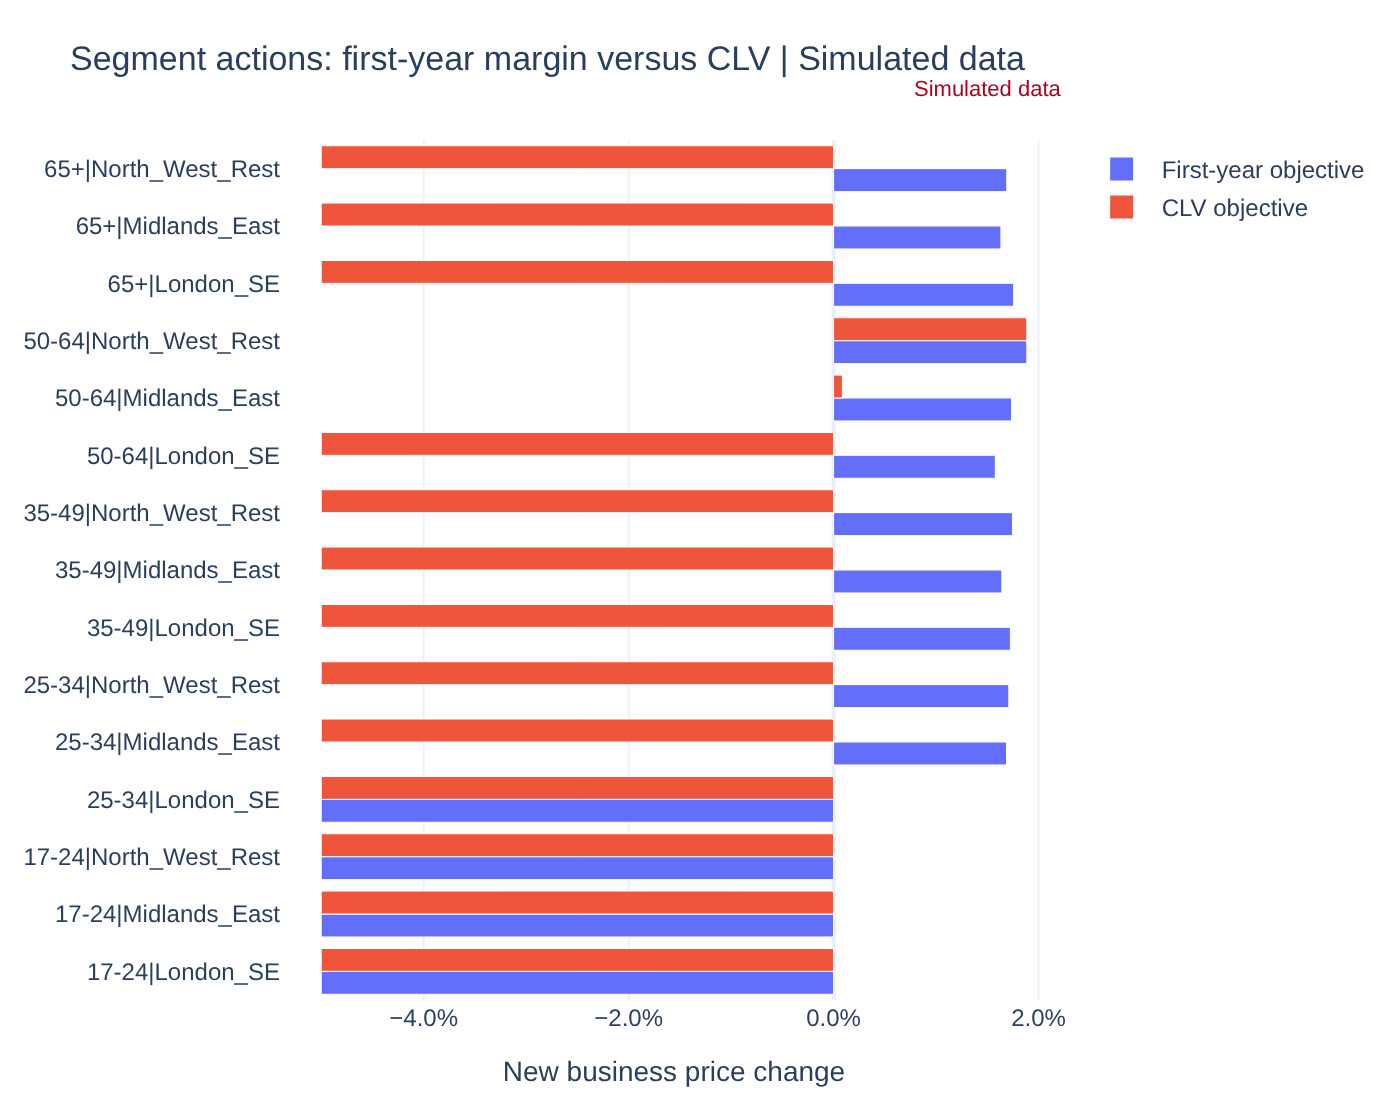

In [5]:
s = summary("m6_summary.json")
display(Markdown(f"Mean CLV per policy **{s['mean_clv_per_policy']:,.1f}** versus mean first-year contribution **{s['mean_first_year_contribution_per_policy']:,.1f}**. {s['segments_with_different_action']} of 15 segments take a different new business action under CLV than under the first-year objective."))
fig("m6_first_year_vs_clv__simulated_data.png")

In [6]:
table("m6_first_year_vs_clv_decisions__simulated_data.csv")

,segment,first_year_nb_change,clv_nb_change,first_year_renewal_change,clv_renewal_change,first_year_action,clv_action,actions_differ,first_year_contribution_per_policy,clv_per_policy
0,17-24|London_SE,-0.0500,-0.0500,0.0152,0.0152,discount,discount,False,562.1697,"1,582.0804"
1,17-24|Midlands_East,-0.0500,-0.0500,0.0112,0.0112,discount,discount,False,325.6126,"1,041.8393"
2,17-24|North_West_Rest,-0.0500,-0.0500,0.0163,0.0163,discount,discount,False,294.2357,970.7433
3,25-34|London_SE,-0.0500,-0.0500,0.0188,0.0188,discount,discount,False,199.5333,799.3190
4,25-34|Midlands_East,0.0169,-0.0500,0.0165,0.0165,increase,discount,True,83.7316,470.5451
5,25-34|North_West_Rest,0.0171,-0.0500,0.0167,0.0167,increase,discount,True,68.4105,429.2826
6,35-49|London_SE,0.0173,-0.0500,0.0177,0.0177,increase,discount,True,151.5562,680.3124
7,35-49|Midlands_East,0.0164,-0.0500,0.0175,0.0175,increase,discount,True,54.0131,385.3419
8,35-49|North_West_Rest,0.0175,-0.0500,0.0169,0.0169,increase,discount,True,38.1128,345.2426
9,50-64|London_SE,0.0158,-0.0500,0.0172,0.0172,increase,discount,True,79.7683,500.5002


In [7]:
display(table("m6_decision_set_comparison__simulated_data.csv"))

,decision_set,nb_policies,nb_total_clv,nb_first_year_contribution,total_first_year_contribution,margin
0,baseline,"1,668.2800","780,428.9974","117,012.0835","1,482,712.9845",0.2314
1,first_year_optimum,"1,601.9122","806,787.8201","130,626.6834","1,559,466.9599",0.2440
2,clv_optimum,"2,098.9164","867,299.0542","98,920.6471","1,527,760.9236",0.2304


## Sensitivities

In [8]:
display(table("m6_clv_sensitivity__simulated_data.csv"))
table("m6_clv_reoptimisation_sensitivity__simulated_data.csv")

,case,mean_clv_per_policy
0,discount_rate=2%,550.2504
1,discount_rate=5%,521.3419
2,discount_rate=8%,495.4192
3,retention_shift=-5%,460.9950
4,retention_shift=+5%,589.2905
5,cost_shift=+0%,521.3419
6,cost_shift=+5%,445.5232
7,cost_shift=+10%,369.7044


,case,converged,segments_discount,segments_increase,segments_hold,segments_changed_vs_clv_base,mean_nb_change
0,discount_rate=2%,True,13,1,1,0,-0.0423
1,discount_rate=8%,True,13,2,0,1,-0.0407
2,retention_shift=-5%,True,13,2,0,1,-0.0405
3,cost_shift=+10%,True,6,8,1,8,-0.0087


## Illustrative control
The renewal versus new business comparison below is an illustrative project control. It is not an ENBP test and not a compliance demonstration. See `docs/regulatory_notes.md`.

In [9]:
table("m6_illustrative_renewal_vs_nb_control__simulated_data.csv")

,segment,avg_new_business_price,avg_renewal_price,renewal_to_new_business_ratio,illustrative_flag
0,17-24|London_SE,"1,617.8700","1,723.0598",1.0650,renewal above NB average
1,17-24|Midlands_East,"1,183.0577","1,298.2662",1.0974,renewal above NB average
2,17-24|North_West_Rest,"1,113.0484","1,193.0726",1.0719,renewal above NB average
3,25-34|London_SE,871.6235,947.8987,1.0875,renewal above NB average
4,25-34|Midlands_East,680.9651,688.6164,1.0112,renewal above NB average
5,25-34|North_West_Rest,641.6072,645.0834,1.0054,renewal above NB average
6,35-49|London_SE,782.1215,779.7967,0.9970,ok
7,35-49|Midlands_East,570.9902,562.8418,0.9857,ok
8,35-49|North_West_Rest,534.1484,530.9262,0.9940,ok
9,50-64|London_SE,669.0911,668.4566,0.9991,ok
